In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from skimage.feature import hog, local_binary_pattern
import seaborn as sns
from tqdm import tqdm
import joblib
import warnings
import glob
import gc
from collections import Counter
from google.colab import files
warnings.filterwarnings('ignore')

class Config:
    DATASET_PATH = '/content/drive/MyDrive/vsl_dataset'

    LETTER_TRAIN_IMAGES = '/content/drive/MyDrive/vsl_dataset/train/images'
    LETTER_TRAIN_LABELS = '/content/drive/MyDrive/vsl_dataset/train/labels'
    LETTER_VALID_IMAGES = '/content/drive/MyDrive/vsl_dataset/valid/images'
    LETTER_VALID_LABELS = '/content/drive/MyDrive/vsl_dataset/valid/labels'
    LETTER_TEST_IMAGES = '/content/drive/MyDrive/vsl_dataset/test/images'
    LETTER_TEST_LABELS = '/content/drive/MyDrive/vsl_dataset/test/labels'

    LETTER_CLASSES = ['A', 'B', 'C', 'D', 'E', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'X', 'Y']
    NUMBER_CLASSES = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']
    ALL_CLASSES = LETTER_CLASSES + NUMBER_CLASSES

    TARGET_SIZE = (96, 96)
    MAX_SAMPLES_PER_CLASS = 200
    MAX_TOTAL_SAMPLES = 10000
    AUGMENTATION_FACTOR = 1.5

    HOG_ORIENTATIONS = 8
    HOG_PIXELS_PER_CELL = (12, 12)
    HOG_CELLS_PER_BLOCK = (2, 2)
    LBP_RADIUS = 2
    LBP_N_POINTS = 16

    RANDOM_STATE = 42

In [ ]:
def detect_hand(image):
    if len(image.shape) == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray = image.copy()

    try:
        if len(image.shape) == 3:
            hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
            lower_skin = np.array([0, 20, 70])
            upper_skin = np.array([20, 255, 255])
            skin_mask = cv2.inRange(hsv, lower_skin, upper_skin)

            contours, _ = cv2.findContours(skin_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            if contours:
                largest = max(contours, key=cv2.contourArea)
                area = cv2.contourArea(largest)
                total_area = gray.shape[0] * gray.shape[1]

                if area > total_area * 0.05:
                    x, y, w, h = cv2.boundingRect(largest)
                    padding = 0.15

                    x1 = max(0, int(x - w * padding))
                    y1 = max(0, int(y - h * padding))
                    x2 = min(gray.shape[1], int(x + w * (1 + padding)))
                    y2 = min(gray.shape[0], int(y + h * (1 + padding)))

                    return {
                        'x_center': (x1 + x2) / (2 * gray.shape[1]),
                        'y_center': (y1 + y2) / (2 * gray.shape[0]),
                        'width': (x2 - x1) / gray.shape[1],
                        'height': (y2 - y1) / gray.shape[0]
                    }, True
    except:
        pass

    return {'x_center': 0.5, 'y_center': 0.5, 'width': 0.7, 'height': 0.7}, False

def enhance_image(image):
    try:
        if len(image.shape) == 3:
            gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        else:
            gray = image.copy()

        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        enhanced = clahe.apply(gray)
        return enhanced
    except:
        return gray if len(image.shape) == 2 else cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

def crop_image(image, bbox, target_size):
    try:
        h, w = image.shape[:2]
        x_center = bbox['x_center'] * w
        y_center = bbox['y_center'] * h
        width = bbox['width'] * w
        height = bbox['height'] * h

        x1 = max(0, int(x_center - width/2))
        y1 = max(0, int(y_center - height/2))
        x2 = min(w, int(x_center + width/2))
        y2 = min(h, int(y_center + height/2))

        cropped = image[y1:y2, x1:x2]
        if cropped.size > 0:
            resized = cv2.resize(cropped, target_size, interpolation=cv2.INTER_AREA)
            return enhance_image(resized)
        else:
            return enhance_image(cv2.resize(image, target_size))
    except:
        return enhance_image(cv2.resize(image, target_size))

In [ ]:
def parse_yolo_annotation(label_path):
    annotations = []
    try:
        with open(label_path, 'r') as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    try:
                        class_id = int(parts[0])
                        coords = [float(x) for x in parts[1:5]]

                        if (0 <= class_id < len(Config.LETTER_CLASSES) and
                            all(0 <= x <= 1 for x in coords) and
                            coords[2] > 0 and coords[3] > 0):

                            annotations.append({
                                'class_id': class_id,
                                'x_center': coords[0],
                                'y_center': coords[1],
                                'width': coords[2],
                                'height': coords[3]
                            })
                    except:
                        continue
    except:
        pass
    return annotations

def load_letter_dataset(images_dir, labels_dir, max_per_class):
    if not os.path.exists(images_dir) or not os.path.exists(labels_dir):
        return []

    image_files = []
    for ext in ['jpg', 'jpeg', 'png', 'JPG', 'JPEG', 'PNG']:
        image_files.extend(glob.glob(os.path.join(images_dir, f'*.{ext}')))

    class_images = {i: [] for i in range(len(Config.LETTER_CLASSES))}

    for img_path in tqdm(image_files, desc=f"Scanning letters {os.path.basename(images_dir)}", leave=False):
        label_path = os.path.join(labels_dir, os.path.splitext(os.path.basename(img_path))[0] + '.txt')

        if os.path.exists(label_path):
            annotations = parse_yolo_annotation(label_path)
            for ann in annotations:
                class_id = ann['class_id']
                class_images[class_id].append((img_path, ann))

    balanced_samples = []
    min_samples = min(len(samples) for samples in class_images.values() if samples)
    target_per_class = min(max_per_class, min_samples)

    print(f"Letter target samples per class: {target_per_class}")

    for class_id, samples in class_images.items():
        if samples:
            np.random.shuffle(samples)
            selected = samples[:target_per_class]
            balanced_samples.extend(selected)
            print(f"Letter {Config.LETTER_CLASSES[class_id]}: {len(selected)} samples")

    return balanced_samples

In [ ]:
def load_number_dataset(base_path, split, max_per_class):
    samples = []

    print(f"Loading number dataset ({split})...")

    for digit in range(10):
        folder_name = f"So_{digit}"
        folder_path = os.path.join(base_path, folder_name, split)

        if not os.path.exists(folder_path):
            print(f"Folder not found: {folder_path}")
            continue

        image_files = []
        for ext in ['jpg', 'jpeg', 'png', 'JPG', 'JPEG', 'PNG']:
            image_files.extend(glob.glob(os.path.join(folder_path, f'*.{ext}')))

        if not image_files:
            print(f"No images found in: {folder_path}")
            continue

        np.random.shuffle(image_files)
        selected_images = image_files[:max_per_class]

        class_id = digit + len(Config.LETTER_CLASSES)

        for img_path in selected_images:
            fake_bbox = {
                'class_id': class_id,
                'x_center': 0.5,
                'y_center': 0.5,
                'width': 0.8,
                'height': 0.8
            }
            samples.append((img_path, fake_bbox))

        print(f"Number {digit} (class {class_id}): {len(selected_images)} samples")

    print(f"Total number samples ({split}): {len(samples)}")
    return samples

In [ ]:
def augment_data(samples):
    np.random.seed(Config.RANDOM_STATE)
    augmented = []

    print(f"Input samples: {len(samples)}")

    class_samples = {}
    for img_path, bbox in samples:
        class_id = bbox['class_id']
        if class_id not in class_samples:
            class_samples[class_id] = []
        class_samples[class_id].append((img_path, bbox))

    print("Input class distribution:")
    for class_id in sorted(class_samples.keys()):
        class_name = Config.ALL_CLASSES[class_id] if class_id < len(Config.ALL_CLASSES) else f"ID_{class_id}"
        print(f"  Class {class_id} ({class_name}): {len(class_samples[class_id])} samples")

    min_samples_per_class = min(len(samples) for samples in class_samples.values())
    target_per_class = min(300, min_samples_per_class * 2)
    print(f"Target samples per class: {target_per_class}")

    class_counts = {}

    for class_id in sorted(class_samples.keys()):
        class_name = Config.ALL_CLASSES[class_id] if class_id < len(Config.ALL_CLASSES) else f"ID_{class_id}"
        print(f"  Processing class {class_id} ({class_name})...")

        samples_for_class = class_samples[class_id]
        np.random.shuffle(samples_for_class)

        processed_count = 0
        for img_path, bbox in samples_for_class:
            if processed_count >= target_per_class:
                break

            try:
                image = cv2.imread(img_path)
                if image is None:
                    continue

                if class_id < 22:
                    detected_bbox, _ = detect_hand(image)
                    cropped = crop_image(image, detected_bbox, Config.TARGET_SIZE)
                else:
                    cropped = crop_image(image, bbox, Config.TARGET_SIZE)

                augmented.append((cropped, class_id))
                processed_count += 1

                if processed_count < target_per_class:
                    h, w = cropped.shape
                    angle = np.random.choice([-5, 5])
                    M = cv2.getRotationMatrix2D((w//2, h//2), angle, 1)
                    rotated = cv2.warpAffine(cropped, M, (w, h))
                    augmented.append((rotated, class_id))
                    processed_count += 1

            except Exception as e:
                print(f"    Error processing {img_path}: {e}")
                continue

        class_counts[class_id] = processed_count
        print(f"    Generated {processed_count} samples for class {class_id}")

    print(f"Augmentation complete: {len(augmented)} total samples")
    print("Final class distribution:")
    for class_id in sorted(class_counts.keys()):
        class_name = Config.ALL_CLASSES[class_id] if class_id < len(Config.ALL_CLASSES) else f"ID_{class_id}"
        print(f"  Class {class_id} ({class_name}): {class_counts[class_id]} samples")

    return augmented

In [ ]:
def extract_hog_features(image):
    try:
        features = hog(
            image,
            orientations=Config.HOG_ORIENTATIONS,
            pixels_per_cell=Config.HOG_PIXELS_PER_CELL,
            cells_per_block=Config.HOG_CELLS_PER_BLOCK,
            block_norm='L2-Hys',
            feature_vector=True
        )
        return np.nan_to_num(features, 0.0)
    except:
        return np.zeros(50)

def extract_lbp_features(image):
    try:
        lbp = local_binary_pattern(image, Config.LBP_N_POINTS, Config.LBP_RADIUS, method='uniform')
        hist, _ = np.histogram(lbp.ravel(), bins=Config.LBP_N_POINTS + 2)
        hist = hist.astype(float)
        hist /= (hist.sum() + 1e-7)
        return np.nan_to_num(hist, 0.0)
    except:
        return np.zeros(18)

def extract_statistical_features(image):
    try:
        flat = image.ravel().astype(float)
        features = [
            np.mean(flat),
            np.std(flat),
            np.median(flat),
            np.min(flat),
            np.max(flat)
        ]
        return np.nan_to_num(features, 0.0)
    except:
        return np.zeros(5)

def extract_features(image):
    if image is None or image.size == 0:
        return np.zeros(80)

    try:
        if len(image.shape) == 3:
            image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        hog_feat = extract_hog_features(image)
        lbp_feat = extract_lbp_features(image)
        stat_feat = extract_statistical_features(image)

        all_features = np.concatenate([hog_feat, lbp_feat, stat_feat])
        return np.nan_to_num(all_features, 0.0)
    except:
        return np.zeros(80)

In [ ]:
def train_model():
    print("Training Model (Letters + Numbers)")

    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except:
        pass

    print("Loading letter dataset...")
    letter_train = load_letter_dataset(Config.LETTER_TRAIN_IMAGES,
                                     Config.LETTER_TRAIN_LABELS,
                                     Config.MAX_SAMPLES_PER_CLASS)
    letter_valid = load_letter_dataset(Config.LETTER_VALID_IMAGES,
                                     Config.LETTER_VALID_LABELS, 30)
    letter_test = load_letter_dataset(Config.LETTER_TEST_IMAGES,
                                    Config.LETTER_TEST_LABELS, 20)

    print("Loading number dataset...")
    number_train = load_number_dataset(Config.DATASET_PATH, 'Train',
                                     Config.MAX_SAMPLES_PER_CLASS)
    number_valid = load_number_dataset(Config.DATASET_PATH, 'Valid', 30)
    number_test = load_number_dataset(Config.DATASET_PATH, 'Test', 20)

    print("\nCombining datasets...")
    print(f"Letter train: {len(letter_train)}, valid: {len(letter_valid)}, test: {len(letter_test)}")
    print(f"Number train: {len(number_train)}, valid: {len(number_valid)}, test: {len(number_test)}")

    all_train = letter_train + number_train
    all_valid = letter_valid + number_valid
    all_test = letter_test + number_test

    print("\nClass distribution:")
    data_classes = {}
    for _, bbox in all_train:
        class_id = bbox['class_id']
        data_classes[class_id] = data_classes.get(class_id, 0) + 1

    for class_id in sorted(data_classes.keys()):
        class_name = Config.ALL_CLASSES[class_id] if class_id < len(Config.ALL_CLASSES) else f"ID_{class_id}"
        print(f"  Class {class_id} ({class_name}): {data_classes[class_id]} samples")

    if not all_train:
        print("No training data!")
        return None

    print(f"Data: {len(all_train)} train, {len(all_valid)} valid, {len(all_test)} test")
    print(f"Total classes: {len(Config.ALL_CLASSES)} (22 letters + 10 numbers)")

    all_train_data = all_train + all_valid

    print("Shuffling data...")
    np.random.seed(Config.RANDOM_STATE)
    np.random.shuffle(all_train_data)

    print("Augmenting data...")
    augmented_train = augment_data(all_train_data)

    print("Processing test data...")
    test_processed = []
    for img_path, bbox in tqdm(all_test, desc="Test processing", leave=False):
        try:
            image = cv2.imread(img_path)
            if image is None:
                continue
            detected_bbox, _ = detect_hand(image)
            cropped = crop_image(image, detected_bbox, Config.TARGET_SIZE)
            test_processed.append((cropped, bbox['class_id']))
        except:
            continue

    print(f"Final: {len(augmented_train)} train, {len(test_processed)} test")

    print("Extracting features...")
    X_train, y_train = [], []
    for image, label in tqdm(augmented_train, desc="Train features", leave=False):
        features = extract_features(image)
        X_train.append(features)
        y_train.append(label)

    X_test, y_test = [], []
    for image, label in tqdm(test_processed, desc="Test features", leave=False):
        features = extract_features(image)
        X_test.append(features)
        y_test.append(label)

    X_train, y_train = np.array(X_train), np.array(y_train)
    X_test, y_test = np.array(X_test), np.array(y_test)

    print(f"Features extracted: Train {X_train.shape}, Test {X_test.shape}")

    del augmented_train, test_processed
    gc.collect()

    train_counts = Counter(y_train)
    test_counts = Counter(y_test)

    print("\nClass distribution:")
    print(f"Train unique: {sorted(set(y_train))}")
    print(f"Test unique: {sorted(set(y_test))}")

    missing_classes = set(range(32)) - set(y_train)
    if missing_classes:
        print(f"Missing classes in training: {missing_classes}")
        missing_names = [Config.ALL_CLASSES[i] for i in missing_classes]
        print(f"Missing class names: {missing_names}")
        print("Training will fail! Need to fix data loading.")
        return None
    else:
        print("All 32 classes present in training data!")

    train_dict = {}
    for k, v in sorted(train_counts.items()):
        if k < len(Config.ALL_CLASSES):
            train_dict[Config.ALL_CLASSES[k]] = v
    print("Train:", train_dict)

    test_dict = {}
    for k, v in sorted(test_counts.items()):
        if k < len(Config.ALL_CLASSES):
            test_dict[Config.ALL_CLASSES[k]] = v
    print("Test:", test_dict)

    X_train_split, X_val, y_train_split, y_val = train_test_split(
        X_train, y_train,
        test_size=0.2,
        random_state=Config.RANDOM_STATE,
        stratify=y_train
    )

    print("Preprocessing...")
    imputer = SimpleImputer(strategy='median')
    X_train_clean = imputer.fit_transform(X_train_split)
    X_val_clean = imputer.transform(X_val)
    X_test_clean = imputer.transform(X_test)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_clean)
    X_val_scaled = scaler.transform(X_val_clean)
    X_test_scaled = scaler.transform(X_test_clean)

    pca = PCA(n_components=0.98, random_state=Config.RANDOM_STATE)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_val_pca = pca.transform(X_val_scaled)
    X_test_pca = pca.transform(X_test_scaled)

    print(f"PCA components: {X_train_pca.shape[1]}")

    print("Training models...")
    models = {
        'Random Forest': RandomForestClassifier(
            n_estimators=50,
            max_depth=8,
            min_samples_split=10,
            min_samples_leaf=5,
            random_state=Config.RANDOM_STATE,
            n_jobs=1
        ),
        'SVM': SVC(
            C=0.5,
            gamma='scale',
            probability=True,
            random_state=Config.RANDOM_STATE
        )
    }

    best_model, best_score, best_name = None, 0, ""

    for name, model in models.items():
        print(f"   Training {name}...")
        try:
            cv_scores = cross_val_score(model, X_train_pca, y_train_split, cv=3, scoring='accuracy')
            print(f"   CV Score: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")

            model.fit(X_train_pca, y_train_split)
            val_score = model.score(X_val_pca, y_val)
            print(f"   Val Score: {val_score:.3f}")

            train_score = model.score(X_train_pca, y_train_split)
            overfitting_gap = train_score - val_score
            print(f"   Overfitting gap: {overfitting_gap:.3f}")

            if val_score > best_score and overfitting_gap < 0.15:
                best_score, best_model, best_name = val_score, model, name

        except Exception as e:
            print(f"   {name} failed: {e}")

    if best_model is None:
        print("No good model found!")
        return None

    print(f"\nBest Model: {best_name}")
    print(f"Validation Score: {best_score:.3f}")

    test_accuracy = best_model.score(X_test_pca, y_test)
    y_pred = best_model.predict(X_test_pca)

    print(f"Test Accuracy: {test_accuracy:.3f}")
    print(f"Generalization Gap: {best_score - test_accuracy:.3f}")

    print(f"\nClassification Report:")
    unique_classes = sorted(set(y_test))
    class_names = [Config.ALL_CLASSES[i] for i in unique_classes if i < len(Config.ALL_CLASSES)]
    print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(15, 12))
    sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
    plt.title('Model Confusion Matrix (Letters + Numbers)')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    try:
        model_data = {
            'model': best_model,
            'imputer': imputer,
            'scaler': scaler,
            'pca': pca,
            'config': {
                'all_classes': Config.ALL_CLASSES,
                'letter_classes': Config.LETTER_CLASSES,
                'number_classes': Config.NUMBER_CLASSES,
                'target_size': Config.TARGET_SIZE,
                'test_accuracy': test_accuracy,
                'val_accuracy': best_score,
                'model_name': best_name,
                'generalization_gap': best_score - test_accuracy
            }
        }

        for name, obj in model_data.items():
            joblib.dump(obj, f'/content/drive/MyDrive/vsl_{name}.pkl')

        print("Model saved!")
        print(f"Final Test Accuracy: {test_accuracy:.1%}")
        print(f"Generalization Gap: {best_score - test_accuracy:.1%}")
        print(f"Total Classes: {len(Config.ALL_CLASSES)}")

        return best_model

    except Exception as e:
        print(f"Save error: {e}")
        return best_model

Training Model (Letters + Numbers)
Mounted at /content/drive
Loading letter dataset...


Letter target samples per class: 200
Letter A: 200 samples
Letter B: 200 samples
Letter C: 200 samples
Letter D: 200 samples
Letter E: 200 samples
Letter G: 200 samples
Letter H: 200 samples
Letter I: 200 samples
Letter K: 200 samples
Letter L: 200 samples
Letter M: 200 samples
Letter N: 200 samples
Letter O: 200 samples
Letter P: 200 samples
Letter Q: 200 samples
Letter R: 200 samples
Letter S: 200 samples
Letter T: 200 samples
Letter U: 200 samples
Letter V: 200 samples
Letter X: 200 samples
Letter Y: 200 samples


Letter target samples per class: 30
Letter A: 30 samples
Letter B: 30 samples
Letter C: 30 samples
Letter D: 30 samples
Letter E: 30 samples
Letter G: 30 samples
Letter H: 30 samples
Letter I: 30 samples
Letter K: 30 samples
Letter L: 30 samples
Letter M: 30 samples
Letter N: 30 samples
Letter O: 30 samples
Letter P: 30 samples
Letter Q: 30 samples
Letter R: 30 samples
Letter S: 30 samples
Letter T: 30 samples
Letter U: 30 samples
Letter V: 30 samples
Letter X: 30 samples
Letter Y: 30 samples


Letter target samples per class: 14
Letter A: 14 samples
Letter B: 14 samples
Letter C: 14 samples
Letter D: 14 samples
Letter E: 14 samples
Letter G: 14 samples
Letter H: 14 samples
Letter I: 14 samples
Letter K: 14 samples
Letter L: 14 samples
Letter M: 14 samples
Letter N: 14 samples
Letter O: 14 samples
Letter P: 14 samples
Letter Q: 14 samples
Letter R: 14 samples
Letter S: 14 samples
Letter T: 14 samples
Letter U: 14 samples
Letter V: 14 samples
Letter X: 14 samples
Letter Y: 14 samples
Loading number dataset...
Loading number dataset (Train)...
Number 0 (class 22): 200 samples
Number 1 (class 23): 200 samples
Number 2 (class 24): 200 samples
Number 3 (class 25): 200 samples
Number 4 (class 26): 200 samples
Number 5 (class 27): 200 samples
Number 6 (class 28): 200 samples
Number 7 (class 29): 200 samples
Number 8 (class 30): 200 samples
Number 9 (class 31): 200 samples
Total number samples (Train): 2000
Loading number dataset (Valid)...
Number 0 (class 22): 25 samples
Number 1 (c

Final: 9600 train, 508 test
Extracting features...


Features extracted: Train (9600, 1591), Test (508, 1591)

Class distribution:
Train unique: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31)]
Test unique: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31)]
All 32 classes pr

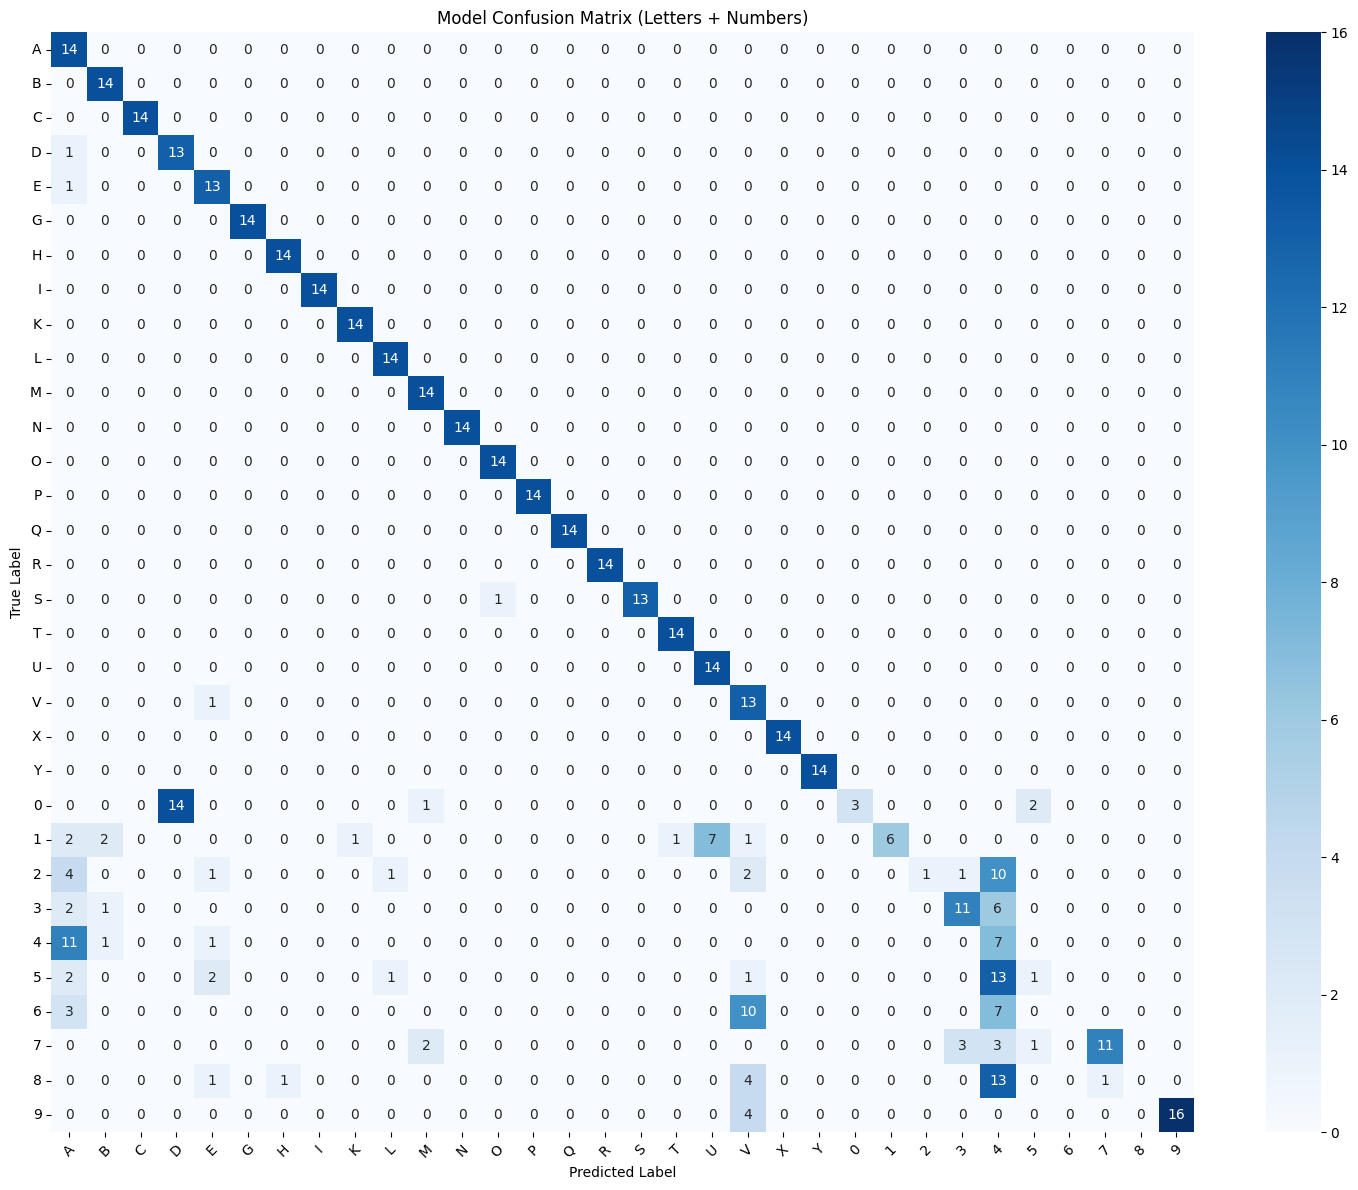

Model saved!
Final Test Accuracy: 70.9%
Generalization Gap: 25.3%
Total Classes: 32


SVC(C=0.5, probability=True, random_state=42)

In [ ]:
train_model()

In [ ]:
def load_model():
    try:
        model = joblib.load('/content/drive/MyDrive/vsl_model.pkl')
        imputer = joblib.load('/content/drive/MyDrive/vsl_imputer.pkl')
        scaler = joblib.load('/content/drive/MyDrive/vsl_scaler.pkl')
        pca = joblib.load('/content/drive/MyDrive/vsl_pca.pkl')
        config = joblib.load('/content/drive/MyDrive/vsl_config.pkl')

        print(f"Model loaded!")
        print(f"Test accuracy: {config['test_accuracy']:.1%}")
        print(f"Classes: {len(config['all_classes'])} total")
        return model, imputer, scaler, pca, config
    except:
        print("Model not found!")
        return None, None, None, None, None

def predict_image(image_path):
    model, imputer, scaler, pca, config = load_model()
    if model is None:
        return None

    try:
        image = cv2.imread(image_path)
        if image is None:
            return None

        bbox, detected = detect_hand(image)
        cropped = crop_image(image, bbox, config['target_size'])

        features = extract_features(cropped).reshape(1, -1)

        features = imputer.transform(features)
        features = scaler.transform(features)
        features = pca.transform(features)

        prediction = model.predict(features)[0]
        probabilities = model.predict_proba(features)[0]
        confidence = probabilities[prediction]

        top_3_idx = np.argsort(probabilities)[-3:][::-1]
        top_3 = [(config['all_classes'][i], probabilities[i]) for i in top_3_idx]

        predicted_char = config['all_classes'][prediction]
        char_type = "Letter" if prediction < 22 else "Number"

        return {
            'predicted_char': predicted_char,
            'char_type': char_type,
            'confidence': confidence,
            'top_3': top_3,
            'hand_detected': detected
        }

    except Exception as e:
        print(f"Prediction error: {e}")
        return None

def test_model():
    print("Testing Model")
    uploaded = files.upload()

    if not uploaded:
        return

    for filename, content in uploaded.items():
        print(f"\nTesting: {filename}")

        with open(f'/tmp/{filename}', 'wb') as f:
            f.write(content)

        result = predict_image(f'/tmp/{filename}')

        if result:
            print(f"Prediction: {result['predicted_char']} ({result['char_type']})")
            print(f"Confidence: {result['confidence']:.1%}")
            print(f"Hand detected: {'✅' if result['hand_detected'] else '⚠️'}")

            print(f"\nTop 3:")
            for i, (char, prob) in enumerate(result['top_3'], 1):
                char_type = "Letter" if char in Config.LETTER_CLASSES else "Number"
                print(f"   {i}. {char} ({char_type}): {prob:.1%}")
        else:
            print("Could not process")

In [ ]:
test_model()

Testing Model


KeyboardInterrupt: 